In [24]:
# !pip install ecmwf-opendata

In [25]:
# !conda install metview metview-python

In [26]:
#!conda install conda-forge::matplotlib

In [27]:
from ecmwf.opendata import Client
import xarray as xr
import matplotlib.pyplot as plt

import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [28]:
client = Client("ecmwf")

In [29]:
print(client.latest(
    type="fc",
    step=24,
    param=["2t", "tp"],
    target="data.grib2",
))

2025-11-01 06:00:00


In [30]:
parameters = ['tp']
filename = 'medium-rain-acc.grib'
filename

'medium-rain-acc.grib'

In [31]:
results = client.retrieve(
    step=[3, 6, 24, 48, 72],
    stream="oper",
    type="fc",
    levtype="sfc",
    param=parameters,
    target=filename
)

In [32]:
print(results.datetime)

2025-11-01 06:00:00


In [33]:
ds = xr.open_dataset(filename, engine="cfgrib", backend_kwargs={"indexpath": ""})
display(ds)


<xarray.Dataset> Size: 21MB
Dimensions:     (step: 5, latitude: 721, longitude: 1440)
Coordinates:
  * step        (step) timedelta64[ns] 40B 0 days 03:00:00 ... 3 days
  * latitude    (latitude) float64 6kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
  * longitude   (longitude) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
    time        datetime64[ns] 8B ...
    surface     float64 8B ...
    valid_time  (step) datetime64[ns] 40B ...
Data variables:
    tp          (step, latitude, longitude) float32 21MB ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-11-01T15:31 GRIB to CDM+CF via cfgrib-0.9.1...

In [34]:
ds['time']

<xarray.DataArray 'time' ()> Size: 8B
[1 values with dtype=datetime64[ns]]
Coordinates:
    time     datetime64[ns] 8B ...
    surface  float64 8B ...
Attributes:
    long_name:      initial time of forecast
    standard_name:  forecast_reference_time

Plotting variable: tp


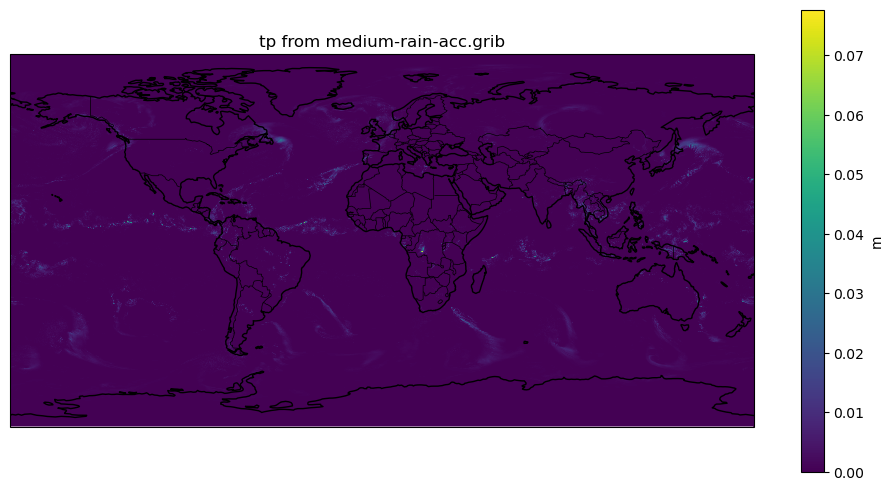

In [38]:
# choose variable (use 'tp' if present)
var = 'tp' if 'tp' in ds.data_vars else list(ds.data_vars)[0]
print("Plotting variable:", var)

da = ds[var]

# If there are extra (time-like) dimensions, select the first step/time to get a 2D lat/lon field
if 'time' in da.dims:
    da = da.isel(time=0)
elif 'step' in da.dims:
    da = da.isel(step=0)

# squeeze any length-1 dimensions so plotting receives a 2D array
da = da.squeeze(drop=True)

fig, ax = plt.subplots(figsize=(12, 6), subplot_kw={'projection': ccrs.PlateCarree()})
# now da should be 2D (latitude, longitude) and plotting will work with cartopy axes
da.plot(ax=ax, transform=ccrs.PlateCarree(), cmap='viridis',
        cbar_kwargs={'label': da.attrs.get('units', '')})
ax.coastlines(resolution='110m', linewidth=1)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.set_global()
plt.title(f"{var} from {filename}")
plt.show()